# Stories Café: Public Holidays and Ramadan, by Branch

**Question:** do Lebanese public holidays (and Ramadan) change how much people buy, when they come, and what they order, at each branch?

**Holidays covered (Jan 1 to Jun 30, 2026):** the 17 national holidays listed by [Office Holidays](https://www.officeholidays.com/countries/lebanon/2026). Islamic holiday dates depend on the moon sighting, and sources disagree by a day for some of them (for example, Ashura is listed as Jun 25 or Jun 26, and the second Eid al-Adha day as May 28 or May 29). The list is in the first code cell, so dates are easy to correct. Other sources checked: [CalendarLabs](https://www.calendarlabs.com/holidays/lebanon/2026), [Edarabia](https://www.edarabia.com/lebanon/public-holidays/).

**Ramadan** is approximated as Feb 18 to Mar 19, 2026 (the day before Eid al-Fitr). It overlaps the start of the war on Mar 1 (see `02_war_impact`).

**Sections**
1. Setup and holiday list
2. Method: how we measure a holiday effect
3. Every holiday, all branches
4. Holidays by branch
5. Behavior on holidays: time of day, takeaway, order value, product mix
6. Ramadan
7. Conclusion

## 1. Setup and holiday list

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

# --- Holiday list: date -> (name, type). Edit here to correct a date and re-run. ---
HOLIDAYS = {
    "2026-01-01": ("New Year's Day", "Civic"),
    "2026-01-06": ("Armenian Christmas", "Christian"),
    "2026-02-09": ("St Maroun Day", "Christian"),
    "2026-02-14": ("Rafik Hariri Memorial", "Civic"),
    "2026-03-20": ("Eid al-Fitr", "Muslim"),
    "2026-03-21": ("Eid al-Fitr, day 2", "Muslim"),
    "2026-03-25": ("Annunciation", "Christian-Muslim"),
    "2026-04-03": ("Good Friday (Western)", "Christian"),
    "2026-04-05": ("Easter (Western)", "Christian"),
    "2026-04-10": ("Good Friday (Orthodox)", "Christian"),
    "2026-04-12": ("Easter (Orthodox)", "Christian"),
    "2026-05-01": ("Labour Day", "Civic"),
    "2026-05-25": ("Resistance and Liberation Day", "Civic"),
    "2026-05-27": ("Eid al-Adha", "Muslim"),
    "2026-05-29": ("Eid al-Adha, day 2", "Muslim"),
    "2026-06-16": ("Hijri New Year", "Muslim"),
    "2026-06-26": ("Ashura", "Muslim"),
}
RAMADAN = (pd.Timestamp("2026-02-18"), pd.Timestamp("2026-03-19"))

holidays = pd.DataFrame.from_dict(HOLIDAYS, orient="index", columns=["holiday", "type"])
holidays.index = pd.to_datetime(holidays.index)
holidays.index.name = "date"
holidays["weekday"] = holidays.index.day_name()

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
ACCENT, NEG, MUTED, BAND = "#2a78d6", "#e34948", "#b9b8b3", "#ecebe6"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
DIV = LinearSegmentedColormap.from_list("div", ["#a8302f", "#e34948", "#f0efec", "#2a78d6", "#184f95"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
R, GP = "Line Revenue (USD)", "Line Gross Profit (USD)"

df = pd.read_csv("../data/stories_transactions.csv").drop_duplicates()  # 132 duplicate lines, as in 01_eda
df["Date"] = pd.to_datetime(df["Date"])
df["hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.hour
df["is_holiday"] = df["Date"].isin(holidays.index)

orders = df.groupby("Transaction ID").agg(
    date=("Date", "first"), hour=("hour", "first"), branch=("Branch", "first"),
    order_type=("Order Type", "first"), revenue=(R, "sum"), items=("Quantity", "sum"),
)
orders["is_holiday"] = orders["date"].isin(holidays.index)
orders["ramadan"] = orders["date"].between(*RAMADAN)
holidays

,holiday,type,weekday
date,,,
2026-01-01,New Year's Day,Civic,Thursday
2026-01-06,Armenian Christmas,Christian,Tuesday
2026-02-09,St Maroun Day,Christian,Monday
2026-02-14,Rafik Hariri Memorial,Civic,Saturday
2026-03-20,Eid al-Fitr,Muslim,Friday
2026-03-21,"Eid al-Fitr, day 2",Muslim,Saturday
2026-03-25,Annunciation,Christian-Muslim,Wednesday
2026-04-03,Good Friday (Western),Christian,Friday
2026-04-05,Easter (Western),Christian,Sunday


## 2. Method: how we measure a holiday effect

Comparing holidays with "normal days" directly would be misleading, for two reasons:
- **Sales grew about 50% over the six months**, so a June holiday would look busy just because June is busy.
- **The weekday matters a lot.** Tuesdays are about 55% busier and Saturdays the quietest, so a holiday that falls on a Tuesday would look like a boom.

So for each branch we:
1. fit a model on **non-holiday days only**: daily orders = growth trend + weekday effect;
2. use it to predict the **expected** orders for each holiday, given its date and weekday;
3. report the **lift** = actual vs expected (for example, +10% means 10% more orders than a normal day at that point in time and on that weekday).

Normal days also bounce around the model. For all branches together, a typical normal day lands within about ±7% of expected, and about 95% land within ±15%. Single branches have fewer orders per day, so their range is wider. **A holiday only counts as unusual if its lift falls outside that normal range** (shown as a gray band in the charts).

In [2]:
def fit_expected(daily_orders, exclude):
    """Fit log(orders) = trend + weekday on days not in `exclude`; return expected orders and the normal-day spread."""
    t = (daily_orders.index - daily_orders.index[0]).days.to_numpy()
    dow = pd.get_dummies(daily_orders.index.dayofweek, drop_first=True).to_numpy(float)
    X = np.column_stack([np.ones(len(t)), t, dow])
    keep = ~daily_orders.index.isin(exclude)
    y = np.log(daily_orders.to_numpy())
    beta, *_ = np.linalg.lstsq(X[keep], y[keep], rcond=None)
    sd = (y[keep] - X[keep] @ beta).std()
    return pd.Series(np.exp(X @ beta), index=daily_orders.index), sd


daily = orders.groupby(["date", "branch"]).size().unstack()[BRANCHES]
daily["All branches"] = daily.sum(axis=1)

lifts, spread = {}, {}
for name in ["All branches", *BRANCHES]:
    exp, sd = fit_expected(daily[name], holidays.index)
    lifts[name] = daily[name] / exp - 1
    spread[name] = sd
lifts = pd.DataFrame(lifts)
band = {k: np.exp(1.96 * v) - 1 for k, v in spread.items()}  # 95% range of normal days
pd.Series(band, name="95% of normal days fall within ±").map("{:.0%}".format).to_frame()

,95% of normal days fall within ±
All branches,15%
Harbour,21%
Garden,28%
Uptown,41%


## 3. Every holiday, all branches

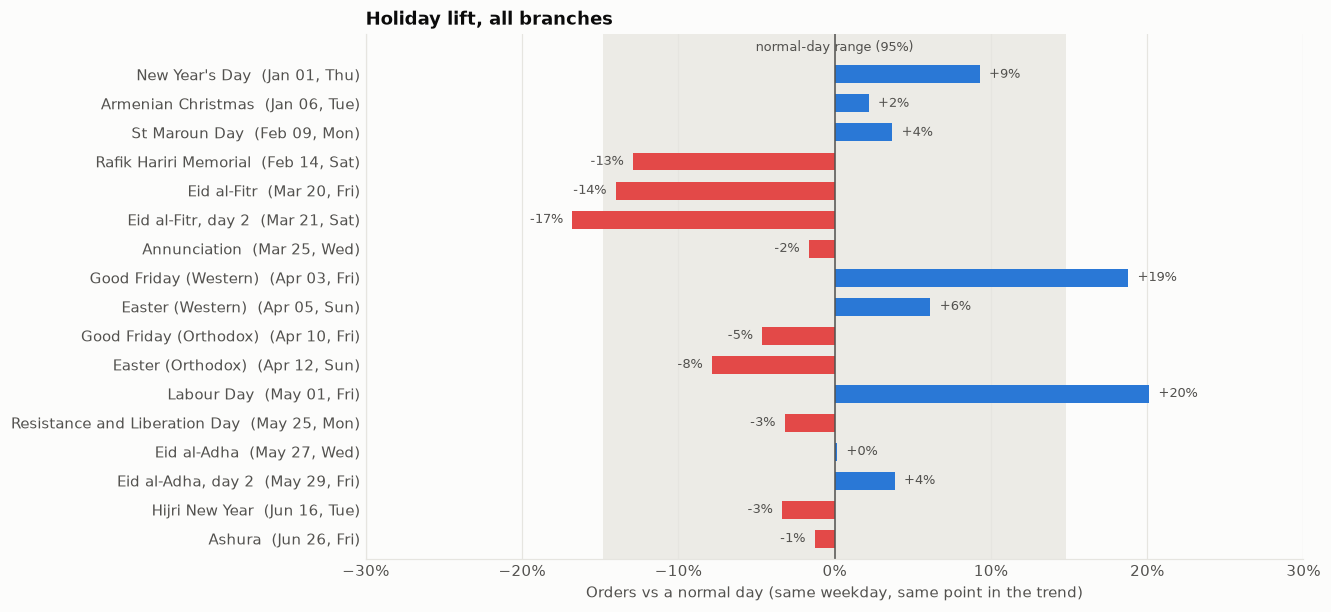

,holiday,type,weekday,actual orders,lift,unusual?
date,,,,,,
Jan 01,New Year's Day,Civic,Thursday,153,+9.3%,
Jan 06,Armenian Christmas,Christian,Tuesday,227,+2.2%,
Feb 09,St Maroun Day,Christian,Monday,158,+3.7%,
Feb 14,Rafik Hariri Memorial,Civic,Saturday,99,-12.9%,
Mar 20,Eid al-Fitr,Muslim,Friday,161,-14.0%,
Mar 21,"Eid al-Fitr, day 2",Muslim,Saturday,104,-16.8%,yes
Mar 25,Annunciation,Christian-Muslim,Wednesday,178,-1.7%,
Apr 03,Good Friday (Western),Christian,Friday,231,+18.8%,yes
Apr 05,Easter (Western),Christian,Sunday,165,+6.1%,


In [3]:
h = holidays.join(lifts["All branches"].rename("lift"))
h["actual orders"] = daily.loc[h.index, "All branches"]
h["unusual?"] = np.where(h["lift"].abs() > band["All branches"], "yes", "")
h = h.sort_index()

fig, ax = plt.subplots(figsize=(11, 6.2))
y = np.arange(len(h))[::-1]
b = band["All branches"]
ax.axvspan(-b, b, color=BAND, lw=0, zorder=0)
ax.text(0, len(h) - 0.3, "normal-day range (95%)", ha="center", va="bottom", color=INK2, fontsize=8.5)
colors = [ACCENT if v >= 0 else NEG for v in h["lift"]]
ax.barh(y, h["lift"], color=colors, height=0.62)
for yi, v in zip(y, h["lift"]):
    ax.text(v + (0.006 if v >= 0 else -0.006), yi, f"{v:+.0%}", va="center",
            ha="left" if v >= 0 else "right", color=INK2, fontsize=8.5)
labels = [f"{n}  ({d:%b %d}, {w[:3]})" for d, n, w in zip(h.index, h["holiday"], h["weekday"])]
ax.set_yticks(y, labels)
ax.axvline(0, color=INK2, lw=1)
ax.xaxis.set_major_formatter(pct)
ax.set_xlim(-0.3, 0.3)
ax.set_ylim(-0.7, len(h) + 0.4)
ax.set_xlabel("Orders vs a normal day (same weekday, same point in the trend)")
ax.set_title("Holiday lift, all branches")
ax.grid(axis="y", visible=False)
plt.show()

h[["holiday", "type", "weekday", "actual orders", "lift", "unusual?"]].rename(
    index=lambda d: d.strftime("%b %d")).style.format(
    {"lift": "{:+.1%}", "actual orders": "{:,.0f}"})

**Takeaway**
- **On average, holidays are just normal days:** the average lift across all 17 holidays is about 0%.
- **Busier than expected:** Labour Day (+20%) and Western Good Friday (+19%), both just outside the normal-day range of ±15%.
- **Quieter than expected:** the second day of Eid al-Fitr (-17%) is just outside the range. The first day (-14%) and the Rafik Hariri Memorial (-13%) are near the edge but inside it. Eid al-Fitr fell during the war (see `02_war_impact`).
- **Be careful with single days.** With 17 holidays, one or two will land outside the 95% range by pure chance. Only patterns that repeat (for example, every Eid, or every branch) are worth building on.

## 4. Holidays by branch

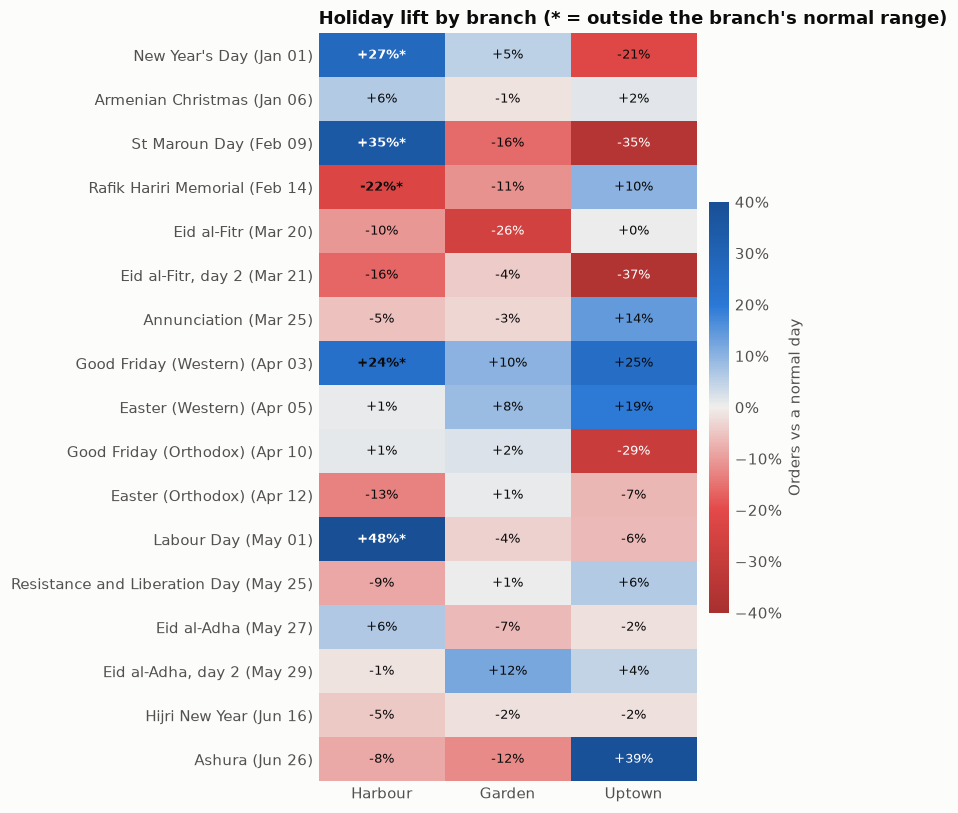

,Harbour,Garden,Uptown
normal range (±),21%,28%,41%


In [4]:
hb = lifts.loc[holidays.index, BRANCHES]
hb.index = [f"{n} ({d:%b %d})" for d, n in zip(holidays.index, holidays["holiday"])]

fig, ax = plt.subplots(figsize=(7.5, 7.5))
im = ax.imshow(hb.values, cmap=DIV, vmin=-0.4, vmax=0.4, aspect="auto")
ax.set_xticks(range(len(BRANCHES)), BRANCHES)
ax.set_yticks(range(len(hb)), hb.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(hb.shape[0]):
    for j, b in enumerate(BRANCHES):
        v = hb.iat[i, j]
        unusual = abs(v) > band[b]
        ax.text(j, i, f"{v:+.0%}" + ("*" if unusual else ""), ha="center", va="center", fontsize=8.5,
                color="white" if abs(v) > 0.25 else INK, fontweight="bold" if unusual else "normal")
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03, format=pct)
cb.set_label("Orders vs a normal day", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Holiday lift by branch (* = outside the branch's normal range)")
plt.tight_layout()
plt.show()

pd.Series(band, name="normal range (±)").loc[BRANCHES].map("{:.0%}".format).to_frame().T

In [5]:
by_type = (lifts.loc[holidays.index].assign(type=holidays["type"].values)
           .groupby("type").mean()[["All branches", *BRANCHES]])
by_type.loc["All holidays"] = lifts.loc[holidays.index].mean()[["All branches", *BRANCHES]]
by_type.style.format("{:+.1%}").set_caption("Average lift by holiday type")

,All branches,Harbour,Garden,Uptown
type,,,,
Christian,+3.1%,+8.9%,+0.7%,-4.2%
Christian-Muslim,-1.7%,-5.4%,-2.9%,+14.1%
Civic,+3.3%,+10.9%,-2.2%,-2.9%
Muslim,-5.2%,-5.7%,-6.4%,+0.5%
All holidays,-0.1%,+3.4%,-2.7%,-1.1%


**Takeaway**
- **Single branches are noisy.** 95% of normal days fall within ±21% at Harbour, ±28% at Garden and ±41% at Uptown, so big-looking numbers at Garden and Uptown are mostly normal variation. None of their holidays falls outside the range.
- **Harbour is the exception.** 5 of its 17 holidays fall outside its normal range (by chance you'd expect about 1): Labour Day +48%, St Maroun +35%, New Year +27% and Western Good Friday +24% were busier, and the Hariri Memorial -22% quieter. Harbour's holidays swing more than its normal days, mostly upward on civic and Christian holidays (about +11% and +9% on average). It's still a handful of days, so treat it as a lead to check, not a rule.
- **Averaged over all holidays**, Harbour is about +3%, Garden about -3% and Uptown about -1%.
- **By type**, Muslim holidays average about -5% across all branches, driven by the two Eid al-Fitr days. Christian and civic holidays average about +3%.

## 5. Behavior on holidays: time of day, takeaway, order value, product mix

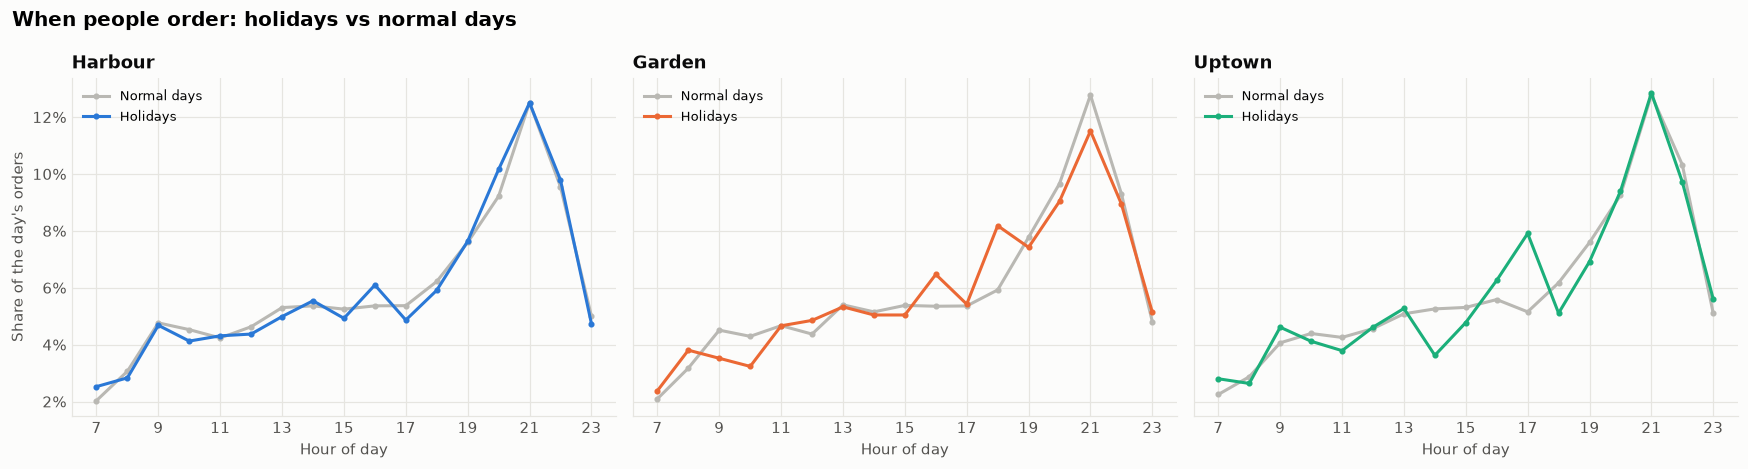

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, b in zip(axes, BRANCHES):
    o = orders[orders["branch"] == b]
    mix = pd.crosstab(o["hour"], o["is_holiday"], normalize="columns")
    ax.plot(mix.index, mix[False], color=MUTED, marker="o", ms=3, label="Normal days")
    ax.plot(mix.index, mix[True], color=BRANCH_COLORS[b], marker="o", ms=3, label="Holidays")
    ax.set_title(b)
    ax.set_xticks(mix.index[::2])
    ax.set_xlabel("Hour of day")
    ax.yaxis.set_major_formatter(pct)
    ax.legend(loc="upper left", fontsize=8.5)
axes[0].set_ylabel("Share of the day's orders")
fig.suptitle("When people order: holidays vs normal days", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

In [7]:
behavior = orders.groupby(["branch", "is_holiday"]).agg(
    aov=("revenue", "mean"), items_per_order=("items", "mean"),
    takeaway_share=("order_type", lambda s: (s == "Takeaway").mean()),
    evening_share=("hour", lambda s: (s >= 18).mean()),
    morning_share=("hour", lambda s: (s <= 10).mean()),
).rename(index={False: "Normal days", True: "Holidays"}, level=1).loc[BRANCHES]
behavior.style.format({"aov": "${:.2f}", "items_per_order": "{:.2f}", "takeaway_share": "{:.1%}",
                       "evening_share": "{:.1%}", "morning_share": "{:.1%}"})

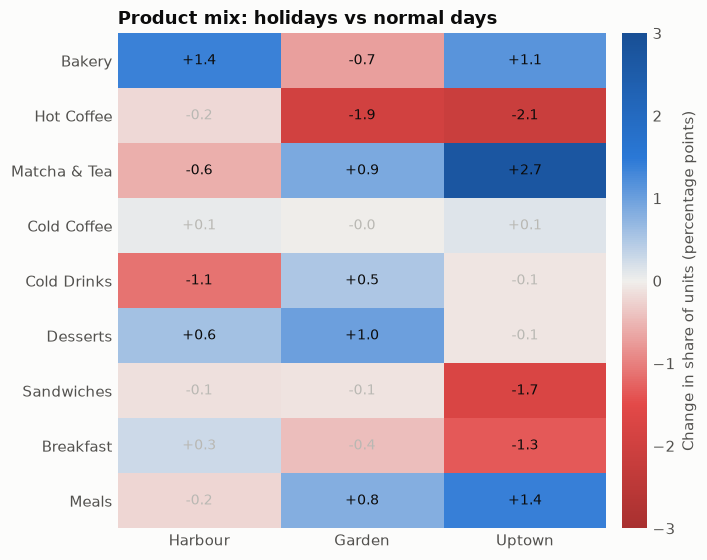

In [8]:
# Change in each category's share of units on holidays vs normal days, in percentage points
mix = pd.crosstab([df["Branch"], df["Category"]], df["is_holiday"], values=df["Quantity"], aggfunc="sum")
mix = mix / mix.groupby(level=0).transform("sum")
change = ((mix[True] - mix[False]) * 100).unstack(0)[BRANCHES]
change = change.loc[mix[False].groupby(level=1).mean().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(change.values, cmap=DIV, vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(len(BRANCHES)), BRANCHES)
ax.set_yticks(range(len(change)), change.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(change.shape[0]):
    for j in range(change.shape[1]):
        v = change.iat[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", color=INK if abs(v) >= 0.5 else MUTED, fontsize=9)
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03)
cb.set_label("Change in share of units (percentage points)", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Product mix: holidays vs normal days")
plt.tight_layout()
plt.show()

**Takeaway:** on holidays, people come at the same times, order the same amount and buy the same products as on normal days, at every branch. A typical café would see a later start and a bigger brunch or family-sized order on holidays; that doesn't appear here. Small differences in the product mix are within what you'd expect from the small number of holiday orders (17 days out of 181).

## 6. Ramadan

During Ramadan many customers fast during the day and eat after sunset (iftar, around 17:30-18:00 in Feb-Mar), so a real café would typically see fewer daytime orders and a stronger, later evening. We compare Ramadan days with the rest of the period, using the same trend + weekday model (fit without holidays).

Ramadan overlaps the first three weeks of the war, so any change here could be due to either.

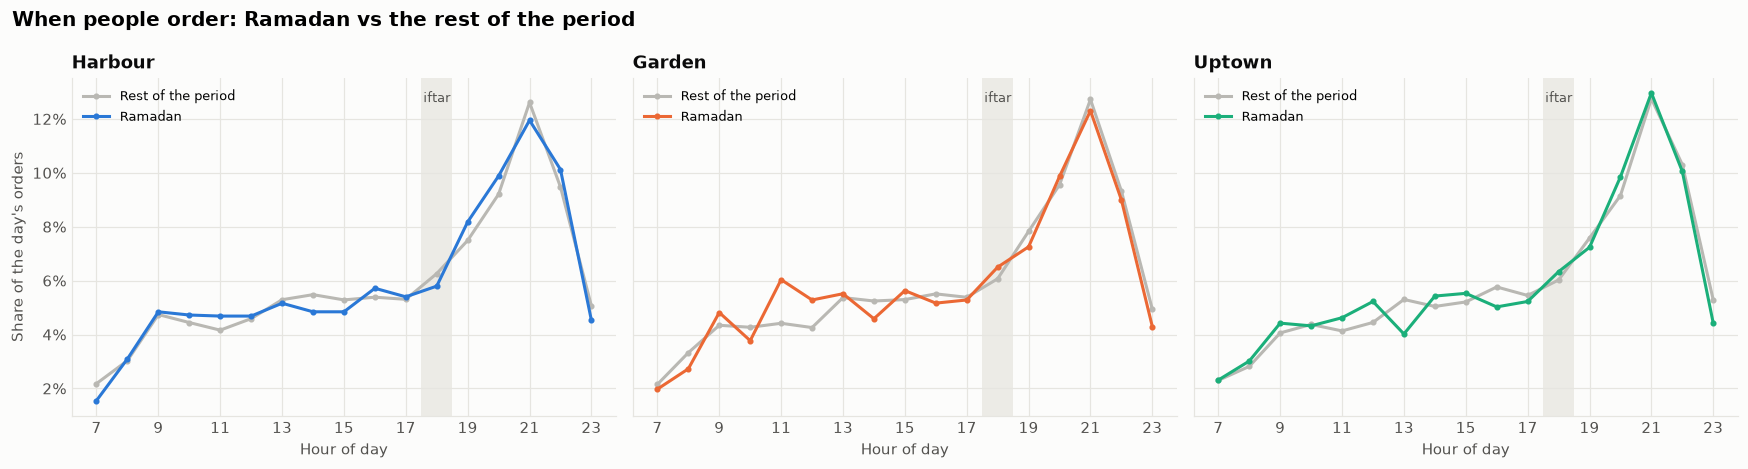

,All branches,Harbour,Garden,Uptown
Ramadan days,+1.3%,+2.5%,+1.2%,+1.7%
Other days,+0.0%,+0.0%,+0.7%,+1.5%


In [9]:
ram_days = daily.index[(daily.index >= RAMADAN[0]) & (daily.index <= RAMADAN[1])]
non_hol = ~daily.index.isin(holidays.index)
ram_lift = pd.DataFrame({
    "Ramadan days": lifts.loc[ram_days.difference(holidays.index)].mean(),
    "Other days": lifts.loc[non_hol & ~daily.index.isin(ram_days)].mean(),
}).T[["All branches", *BRANCHES]]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, b in zip(axes, BRANCHES):
    o = orders[orders["branch"] == b]
    mix = pd.crosstab(o["hour"], o["ramadan"], normalize="columns")
    ax.axvspan(17.5, 18.5, color=BAND, lw=0, zorder=0)
    ax.text(18, 0.96, "iftar", transform=ax.get_xaxis_transform(), ha="center", va="top", color=INK2, fontsize=8.5)
    ax.plot(mix.index, mix[False], color=MUTED, marker="o", ms=3, label="Rest of the period")
    ax.plot(mix.index, mix[True], color=BRANCH_COLORS[b], marker="o", ms=3, label="Ramadan")
    ax.set_title(b)
    ax.set_xticks(mix.index[::2])
    ax.set_xlabel("Hour of day")
    ax.yaxis.set_major_formatter(pct)
    ax.legend(loc="upper left", fontsize=8.5)
axes[0].set_ylabel("Share of the day's orders")
fig.suptitle("When people order: Ramadan vs the rest of the period", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

ram_lift.style.format("{:+.1%}").set_caption("Average orders vs expected")

In [10]:
ram_behavior = orders.groupby(["branch", "ramadan"]).agg(
    daytime_share=("hour", lambda s: s.between(7, 17).mean()),
    evening_share=("hour", lambda s: (s >= 18).mean()),
    aov=("revenue", "mean"),
    takeaway_share=("order_type", lambda s: (s == "Takeaway").mean()),
).rename(index={False: "Rest of the period", True: "Ramadan"}, level=1).loc[BRANCHES]
ram_behavior.style.format({"daytime_share": "{:.1%}", "evening_share": "{:.1%}", "aov": "${:.2f}",
                           "takeaway_share": "{:.1%}"})

**Takeaway:** Ramadan days were about on trend (within a couple of percent) at every branch, and the daily pattern barely moved. The daytime share did not drop and there is no extra jump at iftar time. Average order value and takeaway share were unchanged.

## 7. Conclusion

**The data shows no consistent holiday effect overall. Harbour is the only branch where holidays stand out, and only on a handful of days.**

| What we checked | Result |
|---|---|
| Orders on holidays, all branches | About 0% vs a normal day on average |
| Individual holidays | Labour Day (+20%) and Western Good Friday (+19%) busier; Eid al-Fitr day 2 (-17%) quieter. Each is just outside normal day-to-day variation |
| By branch | Harbour +3%, Garden -3%, Uptown -1% on average. Only Harbour has more unusual holidays than chance (5 of 17), mostly busier on civic and Christian holidays |
| By holiday type | Christian, Muslim and civic holidays all close to 0% |
| Time of day, takeaway, order value, product mix | Same on holidays as on normal days |
| Ramadan | On trend; no daytime drop and no iftar spike |

**How to interpret this:**
1. **The dataset is synthetic** (IDs start with `SYN-`). It was most likely generated from a growth trend plus weekday and hour patterns, with no holiday calendar built in. That would explain why holidays look like ordinary days.
2. **In real Lebanese café data you would usually expect** quieter mornings and busier afternoons on holidays, family-sized orders, a drop in daytime sales during Ramadan with a strong post-iftar evening, and spikes around Eid and Easter. Any of these would be a strong basis for holiday promotions.
3. **Harbour lead:** if the team wants a holiday angle, Harbour on civic and Christian holidays (Labour Day, St Maroun, New Year, Good Friday) is the one place the data hints at extra demand, for example extra staff or a holiday menu there. It's based on a few days, so frame it as a test.
4. **For the pitch:** holiday-specific campaigns (Eid, Easter, Ramadan evenings) are a reasonable idea in general, but this dataset can't prove they'd pay off. If you propose them, say so, and suggest testing them with a small promotion first.

To correct a holiday date, edit `HOLIDAYS` in the first code cell and re-run all cells.